# Fetal Ultrasound Image Classification

## 1. Project Overview

This project focuses on classifying fetal ultrasound images
into six anatomical categories using deep learning.

### Classification Categories
1. Fetal Abdomen
2. Fetal Brain
3. Fetal Femur
4. Fetal Thorax
5. Maternal Cervix
6. Other

## 2. Objectives
- Understand the dataset.
- Perform exploratory data analysis.
- Build deep learning classification models.
- Evaluate model performance.
- Apply explainable AI techniques.

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
PROJECT_DIR = Path.cwd().parent

CSV_PATH = PROJECT_DIR / "original" / "FETAL_PLANES_DB_data.csv"

print("Project directory:", PROJECT_DIR)
print("CSV exists:", CSV_PATH.exists())

Project directory: C:\B.tech\Project\Fetal_Ultrasound_Project
CSV exists: True


In [7]:
df = pd.read_csv(CSV_PATH, sep=";")

# Clean column names
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (12400, 7)


,Image_name,Patient_num,Plane,Brain_plane,Operator,US_Machine,Train
0,Patient00001_Plane1_1_of_15,1,Other,Not A Brain,Other,Aloka,1
1,Patient00001_Plane1_2_of_15,1,Other,Not A Brain,Other,Aloka,1
2,Patient00001_Plane1_3_of_15,1,Other,Not A Brain,Other,Aloka,1
3,Patient00001_Plane1_4_of_15,1,Other,Not A Brain,Other,Aloka,1
4,Patient00001_Plane1_5_of_15,1,Other,Not A Brain,Other,Aloka,1


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12400 entries, 0 to 12399
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Image_name   12400 non-null  str  
 1   Patient_num  12400 non-null  int64
 2   Plane        12400 non-null  str  
 3   Brain_plane  12400 non-null  str  
 4   Operator     12400 non-null  str  
 5   US_Machine   12400 non-null  str  
 6   Train        12400 non-null  int64
dtypes: int64(2), str(5)
memory usage: 678.3 KB


In [9]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(df) * 100
    )
})

display(missing_summary)

,Missing Values,Missing Percentage
Image_name,0,0.0
Patient_num,0,0.0
Plane,0,0.0
Brain_plane,0,0.0
Operator,0,0.0
US_Machine,0,0.0
Train,0,0.0


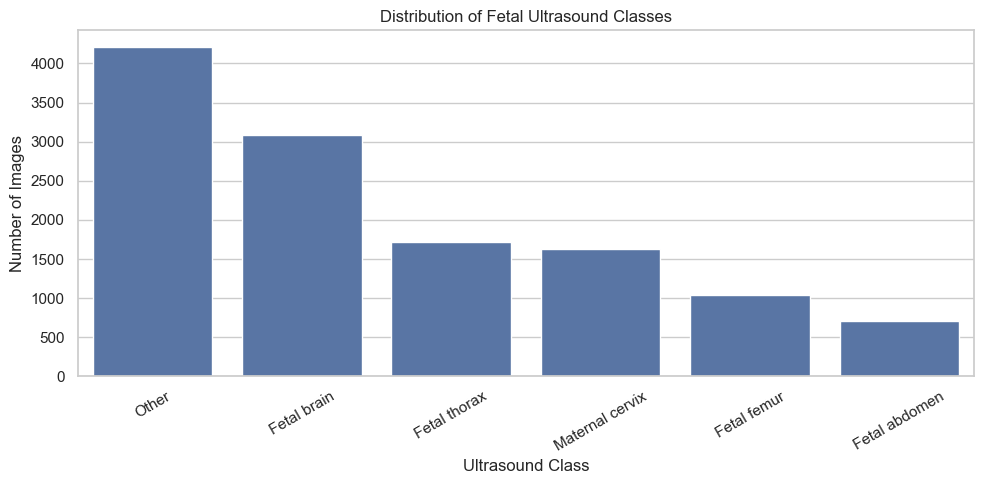

In [10]:
class_counts = df["Plane"].value_counts()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Distribution of Fetal Ultrasound Classes")
plt.xlabel("Ultrasound Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [3]:

from pathlib import Path

PROJECT_DIR = Path(r"C:\B.tech\Project\Fetal_Ultrasound_Project")
ORIGINAL_DIR = PROJECT_DIR / "Original"

print("=== ORIGINAL PROJECT FILES ===")

for f in sorted(ORIGINAL_DIR.rglob("*")):
    if f.is_file():
        print(f.relative_to(ORIGINAL_DIR))

print("\n=== CSV FILES ===")
csv_files = list(ORIGINAL_DIR.rglob("*.csv"))
for f in csv_files:
    print(f.name, "->", f)

print("\n=== IMAGE FILES ===")
image_extensions = {".png", ".jpg", ".jpeg", ".bmp"}
images = [
    f for f in ORIGINAL_DIR.rglob("*")
    if f.is_file() and f.suffix.lower() in image_extensions
]
print("Total images found:", len(images))


=== ORIGINAL PROJECT FILES ===
.gitignore
1_ResizingImage.ipynb
2_Classification.ipynb
3_SplitImage.ipynb
4_Augumentation.ipynb
5_Normalization.ipynb
6_modelTraining.ipynb
7_accuracy.ipynb
8_testvsevalution.ipynb
9_test.ipynb
FETAL_PLANES_DB_data.csv
images.jpg
img.png
PROJECT_REPORT.md
training_metrics.png

=== CSV FILES ===
FETAL_PLANES_DB_data.csv -> C:\B.tech\Project\Fetal_Ultrasound_Project\Original\FETAL_PLANES_DB_data.csv

=== IMAGE FILES ===
Total images found: 3


In [11]:

# Load original metadata
CSV_PATH = ORIGINAL_DIR / "FETAL_PLANES_DB_data.csv"

df = pd.read_csv(CSV_PATH, sep=";")

# Clean column names
df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum())

print("\nClass distribution:")
display(df["Plane"].value_counts())

print("\nTrain/Test distribution:")
display(df["Train"].value_counts())

print("\nUnique patients:", df["Patient_num"].nunique())


Dataset shape: (12400, 7)

Column names:
['Image_name', 'Patient_num', 'Plane', 'Brain_plane', 'Operator', 'US_Machine', 'Train']

First 5 rows:


,Image_name,Patient_num,Plane,Brain_plane,Operator,US_Machine,Train
0,Patient00001_Plane1_1_of_15,1,Other,Not A Brain,Other,Aloka,1
1,Patient00001_Plane1_2_of_15,1,Other,Not A Brain,Other,Aloka,1
2,Patient00001_Plane1_3_of_15,1,Other,Not A Brain,Other,Aloka,1
3,Patient00001_Plane1_4_of_15,1,Other,Not A Brain,Other,Aloka,1
4,Patient00001_Plane1_5_of_15,1,Other,Not A Brain,Other,Aloka,1



Missing values:


Image_name     0
Patient_num    0
Plane          0
Brain_plane    0
Operator       0
US_Machine     0
Train          0
dtype: int64


Class distribution:


Plane
Other              4213
Fetal brain        3092
Fetal thorax       1718
Maternal cervix    1626
Fetal femur        1040
Fetal abdomen       711
Name: count, dtype: int64


Train/Test distribution:


Train
1    7129
0    5271
Name: count, dtype: int64


Unique patients: 1792


In [14]:
%pip install torch torchvision

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   - -------------------------------------- 3.4/126.7 MB 14.7 MB/s eta 0:00:09
   -- ------------------------------------- 8.7/126.7 MB 19.5 MB/s eta 0:00:07
   ---- ----------------------------------- 15.2/126.7 MB 23.1 MB/s eta 0:00:05
   ------ --------------------------------- 21.8/126.7 MB 25.2 MB/s eta 0:00:05
   --------- ------------------------------ 28.6/126.7 MB 26.7 MB/s eta 0:00:04
   ---------- ----------------------------- 33.0/126.7 MB 25.5 MB/s eta 0:00:04
   ----------- ---------------------------- 38.0/126.7 MB 25.5 MB/s eta 0:00:04
   -------------- ------------------------- 44.8/126.7 MB 26.2 MB/s eta 0:00:04
   ---------------- ----------------------- 51.1/126.7 MB 26.8 MB/s eta 0:00:03
   ------------------ --------------------- 57.4/126.7 MB 27.0 MB/s eta 0:00:03
   -------------------- ------------------- 63.7/126.

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [15]:
import torch
import os

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")
import torch
import os

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

GPU available: False
Using CPU
GPU available: False
Using CPU


In [17]:
from pathlib import Path

DATA_DIR = PROJECT_DIR / "data"

all_files = [
    f for f in DATA_DIR.rglob("*")
    if f.is_file()
]

print("Total files:", len(all_files))

print("\nFirst 30 files:")
for f in all_files[:30]:
    print(f.relative_to(DATA_DIR))

image_extensions = {".png", ".jpg", ".jpeg", ".bmp"}

image_files = [
    f for f in all_files
    if f.suffix.lower() in image_extensions
]

print("\nTotal image files:", len(image_files))

Total files: 12403

First 30 files:
FETAL_PLANES_DB_data.csv
FETAL_PLANES_DB_data.xlsx
README.md
Images\Patient00001_Plane1_10_of_15.png
Images\Patient00001_Plane1_11_of_15.png
Images\Patient00001_Plane1_12_of_15.png
Images\Patient00001_Plane1_13_of_15.png
Images\Patient00001_Plane1_14_of_15.png
Images\Patient00001_Plane1_15_of_15.png
Images\Patient00001_Plane1_1_of_15.png
Images\Patient00001_Plane1_2_of_15.png
Images\Patient00001_Plane1_3_of_15.png
Images\Patient00001_Plane1_4_of_15.png
Images\Patient00001_Plane1_5_of_15.png
Images\Patient00001_Plane1_6_of_15.png
Images\Patient00001_Plane1_7_of_15.png
Images\Patient00001_Plane1_8_of_15.png
Images\Patient00001_Plane1_9_of_15.png
Images\Patient00002_Plane1_10_of_20.png
Images\Patient00002_Plane1_11_of_20.png
Images\Patient00002_Plane1_12_of_20.png
Images\Patient00002_Plane1_13_of_20.png
Images\Patient00002_Plane1_14_of_20.png
Images\Patient00002_Plane1_15_of_20.png
Images\Patient00002_Plane1_16_of_20.png
Images\Patient00002_Plane1_17_of

## 4. Image and Metadata Consistency Check

### Objective
To verify whether every image referenced in the metadata exists in the extracted image directory.

### Methodology
- Extract image filenames from the metadata.
- Compare them with actual image files.
- Identify missing and unmatched images.
- Verify dataset consistency before model training.

In [18]:

# Define dataset paths
DATA_CSV = DATA_DIR / "FETAL_PLANES_DB_data.csv"
IMAGE_DIR = DATA_DIR / "Images"

# Load downloaded dataset metadata
df_data = pd.read_csv(DATA_CSV, sep=";")
df_data.columns = df_data.columns.str.strip()

# Get metadata image names
metadata_names = set(df_data["Image_name"].astype(str))

# Get actual image names (without extension)
actual_names = {
    f.stem for f in IMAGE_DIR.glob("*.png")
}

# Compare
missing_images = metadata_names - actual_names
unmatched_images = actual_names - metadata_names

print("Metadata records:", len(df_data))
print("Unique metadata image names:", len(metadata_names))
print("Actual image files:", len(actual_names))

print("Missing images:", len(missing_images))
print("Unmatched images:", len(unmatched_images))

print("\nSample missing:", list(missing_images)[:5])
print("Sample unmatched:", list(unmatched_images)[:5])


Metadata records: 12400
Unique metadata image names: 12400
Actual image files: 12400
Missing images: 0
Unmatched images: 0

Sample missing: []
Sample unmatched: []



## 5. Patient-Level Dataset Analysis

### Objective
Analyze the distribution of ultrasound images across patients and investigate the original train/test split for possible patient-level data leakage.


In [19]:

# Images per patient
patient_counts = df.groupby("Patient_num").size()

print("Total unique patients:", df["Patient_num"].nunique())
print("Average images per patient:", round(patient_counts.mean(), 2))
print("Minimum images:", patient_counts.min())
print("Maximum images:", patient_counts.max())

# Check patient overlap in original split
train_patients = set(df.loc[df["Train"] == 1, "Patient_num"])
test_patients = set(df.loc[df["Train"] == 0, "Patient_num"])

overlap = train_patients.intersection(test_patients)

print("\nTrain patients:", len(train_patients))
print("Test patients:", len(test_patients))
print("Patient overlap:", len(overlap))


Total unique patients: 1792
Average images per patient: 6.92
Minimum images: 1
Maximum images: 88

Train patients: 896
Test patients: 896
Patient overlap: 0



## 6. Class Distribution Across Training and Testing Sets

Analyze the distribution of each ultrasound class across the original training and testing sets to identify class imbalance and evaluate split consistency.


In [20]:

split_summary = pd.crosstab(
    df["Plane"],
    df["Train"].map({1: "Train", 0: "Test"})
)

display(split_summary)

print("\nClass percentages:")
display(
    pd.crosstab(
        df["Plane"],
        df["Train"].map({1: "Train", 0: "Test"}),
        normalize="columns"
    ).round(3) * 100
)


Train,Test,Train
Plane,,
Fetal abdomen,358,353
Fetal brain,1472,1620
Fetal femur,524,516
Fetal thorax,660,1058
Maternal cervix,645,981
Other,1612,2601



Class percentages:


Train,Test,Train
Plane,,
Fetal abdomen,6.8,5.0
Fetal brain,27.9,22.7
Fetal femur,9.9,7.2
Fetal thorax,12.5,14.8
Maternal cervix,12.2,13.8
Other,30.6,36.5



## 7. Dataset Analysis — Conclusion

The FETAL_PLANES_DB dataset contains 12,400 ultrasound images from 1,792 unique patients across six anatomical classes.

### Key Findings

1. No missing values were found in the metadata.
2. All 12,400 metadata records successfully matched the extracted ultrasound images.
3. The dataset contains 7,129 training images and 5,271 testing images.
4. The original patient-level split has zero patient overlap between training and testing sets.
5. The dataset exhibits class imbalance, with Other being the majority class and Fetal abdomen being the minority class.
6. Class proportions differ between the original training and testing sets.

### Planned Improvements

- Preserve the original patient-level split.
- Apply augmentation only to training images.
- Investigate class-weighted loss to handle class imbalance.
- Reproduce the original ResNet18 baseline.
- Compare the baseline with an improved training pipeline.
- Evaluate using precision, recall, F1-score and confusion matrix.

### Conclusion

The dataset is successfully extracted, verified and ready for preprocessing and model development.
